# AI & Machine Learning

## Notebook Setup

In [ ]:
%pip install tf_keras_vis
#%pip install tflite-support-nightly # for mobile integration

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.5/52.5 kB 2.5 MB/s eta 0:00:00


In [ ]:
%pip uninstall -y keras tensorflow
%pip install --upgrade tensorflow
%pip install tf-keras-vis
%pip install opencv-python

Found existing installation: keras 3.10.0
Uninstalling keras-3.10.0:
  Successfully uninstalled keras-3.10.0
Found existing installation: tensorflow 2.19.0
Uninstalling tensorflow-2.19.0:
  Successfully uninstalled tensorflow-2.19.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 620.7/620.7 MB 850.4 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 61.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 76.3 MB/s eta 0:00:00
  Attempting uninstall: tensorboard
    Found existing installation: tensorboard 2.19.0
    Uninstalling tensorboard-2.19.0:
      Successfully uninstalled tensorboard-2.19.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tensorflow-text 2.19.0 requires tensorflow<2.20,>=2.19.0, but you have tensorflow 2.20.0 which is incompatible.
tf-keras 2.19.0 requires tensorflow<2.20,>=2.19, but you have tensorfl

## Create your dataset

### Colab setup

In [ ]:
!pip install bing-image-downloader==1.0.4

from bing_image_downloader import downloader
from google.colab import files
import os

### Classes & dataset setup

In [ ]:
import cv2
import os
import pandas as pd
from glob import glob
import matplotlib.pyplot as plt

import PIL
import PIL.Image

import numpy as np
import tensorflow as tf

from tensorflow.keras import Sequential
from tensorflow.keras.layers import RandomFlip, RandomRotation, RandomZoom, Rescaling, Resizing
from tensorflow.keras.preprocessing.image import img_to_array, load_img

from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.optimizers import RMSprop
from tensorflow.keras.losses import SparseCategoricalCrossentropy
from tensorflow.keras import Model
from tensorflow.keras.layers import (
    GlobalAveragePooling2D,
    Dense,
    Dropout
)

from sklearn.model_selection import KFold
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

import matplotlib.pyplot as pl

import sklearn.metrics as me

from matplotlib import pyplot as plt
from matplotlib import cm
from tf_keras_vis.gradcam_plus_plus import GradcamPlusPlus
from tf_keras_vis.utils.model_modifiers import ReplaceToLinear
from tf_keras_vis.utils.scores import CategoricalScore

1) Choose which classes you would like to add.

In [ ]:
classes = ["myCat", "cat"]

2) Create a dataset with your own photos

In [ ]:
def download_queries(queries, path, nbr):
  for query in queries:
    downloader.download(
        query, nbr - len(os.listdir(path + "/" + query)), path,
        adult_filter_off=False, force_replace=False, timeout=15
    )

def upload_pictures(path):
  # Upload files
  uploaded = files.upload()

  # Create the destination directory if it doesn't exist
  if not os.path.exists(path):
      os.makedirs(path)

  # Move the uploaded files to the destination directory
  for filename in uploaded.keys():
      source_path = filename
      destination_path = os.path.join(path, filename)
      os.rename(source_path, destination_path)

In [ ]:
for train_class in classes:
  print("for", train_class, "import training pictures:")
  upload_pictures('dataset_train/' + train_class)
  print("for", train_class, "import test pictures:")
  upload_pictures('dataset_test/' + train_class)

for myCat import training pictures:


Saving 0dff1bc9-2d60-4b60-bab4-55cc2006630e.jpg to 0dff1bc9-2d60-4b60-bab4-55cc2006630e.jpg
Saving 1d5cd7e4-a5ac-4de2-b93d-722cedaa60ed.jpg to 1d5cd7e4-a5ac-4de2-b93d-722cedaa60ed.jpg
Saving 2d5bd663-6e7b-42a5-aac0-0c800aa71672.jpg to 2d5bd663-6e7b-42a5-aac0-0c800aa71672.jpg
Saving 6f293b7e-a797-454e-bc5c-4a39020354fe.jpg to 6f293b7e-a797-454e-bc5c-4a39020354fe.jpg
Saving 7f6f8774-8637-457e-aba2-66be4ba4bd9f.jpg to 7f6f8774-8637-457e-aba2-66be4ba4bd9f.jpg
Saving 19fe070a-c21f-4bbc-9180-58b878ba7275.jpg to 19fe070a-c21f-4bbc-9180-58b878ba7275.jpg
Saving 50a06042-d93e-4631-bcd3-3af443528804.jpg to 50a06042-d93e-4631-bcd3-3af443528804.jpg
Saving 2744f46c-c5cb-4297-924d-cebf319a7dbe.jpg to 2744f46c-c5cb-4297-924d-cebf319a7dbe.jpg
Saving 96302459-a11c-4e1c-8f96-68ed487c2663.jpg to 96302459-a11c-4e1c-8f96-68ed487c2663.jpg
Saving a6cc1331-8806-4c48-9815-d22bcebe2c0f.jpg to a6cc1331-8806-4c48-9815-d22bcebe2c0f.jpg
Saving b4cf58da-e7da-417c-aebf-62faef8dc78e.jpg to b4cf58da-e7da-417c-aebf-62fae

Saving 47d6045b-c220-48a6-a24a-785ce7ab337e.jpg to 47d6045b-c220-48a6-a24a-785ce7ab337e.jpg
Saving 20884d32-c3c0-45ef-a504-e34836712792.jpg to 20884d32-c3c0-45ef-a504-e34836712792.jpg
Saving a45bd410-e568-4392-959f-c872a3d5f0b7.jpg to a45bd410-e568-4392-959f-c872a3d5f0b7.jpg
Saving c300b3b4-d81a-4796-aa08-7962ea1b2904.jpg to c300b3b4-d81a-4796-aa08-7962ea1b2904.jpg
Saving da0c988a-0f2f-45b5-9f39-c5fc4e293644.jpg to da0c988a-0f2f-45b5-9f39-c5fc4e293644.jpg
Saving ef51a6b8-8f1b-432a-9af0-94cc6036ac75.jpg to ef51a6b8-8f1b-432a-9af0-94cc6036ac75.jpg
for cat import training pictures:


Saving 2cb77cd3-811e-4ee5-b3af-4e5fff4ec63e.jpg to 2cb77cd3-811e-4ee5-b3af-4e5fff4ec63e.jpg
Saving 2d026e70-3051-4dc6-896b-853a660d2413.jpg to 2d026e70-3051-4dc6-896b-853a660d2413.jpg
Saving 3a6051a6-b636-4719-bbc7-b8533a071e16.jpg to 3a6051a6-b636-4719-bbc7-b8533a071e16.jpg
Saving 4b931706-5099-4096-b0d1-8be42fecb5b2.jpg to 4b931706-5099-4096-b0d1-8be42fecb5b2.jpg
Saving 7dd9a6ed-c8bb-4ddf-bd91-92084ef4f8d5.jpg to 7dd9a6ed-c8bb-4ddf-bd91-92084ef4f8d5.jpg
Saving 70d6cdf9-de17-4941-8e97-2b838d3f7897.jpg to 70d6cdf9-de17-4941-8e97-2b838d3f7897.jpg
Saving 74d7f10f-da1a-4b75-a746-dde3b7a2a131.jpg to 74d7f10f-da1a-4b75-a746-dde3b7a2a131.jpg
Saving 83f47152-154e-490c-b527-4970ce913f73.jpg to 83f47152-154e-490c-b527-4970ce913f73.jpg
Saving 619f3943-5ce8-4d91-9acf-48a791f14096.jpg to 619f3943-5ce8-4d91-9acf-48a791f14096.jpg
Saving 2395b7c7-f5af-4809-9e15-9514729996b0.jpg to 2395b7c7-f5af-4809-9e15-9514729996b0.jpg
Saving 6490ec57-e2c7-430c-be31-f807ceedb182.jpg to 6490ec57-e2c7-430c-be31-f807c

Saving 469ba22d-faef-49e1-9aa0-2bfac0b90850.jpg to 469ba22d-faef-49e1-9aa0-2bfac0b90850.jpg
Saving b3d2d407-2a10-41c3-8302-2882d6830f09.jpg to b3d2d407-2a10-41c3-8302-2882d6830f09.jpg
Saving d960a036-dfa4-4db4-aa05-2ee8f696b9da.jpg to d960a036-dfa4-4db4-aa05-2ee8f696b9da.jpg
Saving fbaa6c95-b701-41e7-8378-2cc8ec51cf78.jpg to fbaa6c95-b701-41e7-8378-2cc8ec51cf78.jpg
Saving IMG_0034.JPG to IMG_0034.JPG
Saving IMG_20230516_190542.jpg to IMG_20230516_190542.jpg


If necessary (not enough images), execute the following cell with the needed class names in the QUERRIES variable.

In [ ]:
QUERIES = ["cat"] # for example, with enought images for my cat, and a need for cat

NBR = int(len(os.listdir("dataset_train/" + classes[0])))
download_queries(QUERIES, "dataset_train", NBR)
download_queries(QUERIES, "dataset_test", int(max(int(NBR/4), 1)))

Or to complet the set use the next cell: (won't work for personnal pictures)

In [ ]:
# QUERIES = classes.copy()

# NBR = 30
# download_queries(QUERIES, "dataset_train", NBR)
# download_queries(QUERIES, "dataset_test", int(max(int(NBR/4), 1)))

In [ ]:
#png to jpg
def png_to_jpg(path):
    nbrOfPng = 0

    for label_dir in os.listdir(path):
        if os.path.isfile(label_dir):
            continue

        label_path_path = os.path.join(path, label_dir)

        for photoName in os.listdir(label_path_path):
            if (photoName.rsplit('.',1)[1] == "png") :
                old_path = os.path.join(label_path_path, photoName)
                new_path = old_path.rsplit('.',1)[0] + ".jpg"

                png_img = cv2.imread(old_path)
                cv2.imwrite(new_path, png_img, [int(cv2.IMWRITE_JPEG_QUALITY), 100])
                os.remove(old_path) # remove previous image
                nbrOfPng += 1
    print("number of png found and resized in jpg : " + str(nbrOfPng))

png_to_jpg("dataset_train")
png_to_jpg("dataset_test")

number of png found and resized in jpg : 0
number of png found and resized in jpg : 0


3) Separate your dataset into train and test subsets.

In [ ]:
# def create_dataframe_from_directories(path):
#     data = []

#     for label_dir in os.listdir(path):
#         if os.path.isfile(label_dir):
#             continue

#         label_path_path = os.path.join(path, label_dir)
#         for file in os.listdir(label_path_path):
#             data.append([os.path.join(label_path_path, file), label_dir])

#     return pd.DataFrame(data, columns = ["path", "label"])

def create_dataframe_from_directories(path):
    data = []
    image_extensions = ('.jpg', '.jpeg', '.png', '.gif', '.bmp')

    for label_dir in os.listdir(path):
        label_path = os.path.join(path, label_dir)

        # Ensure it's a directory before processing as a label
        if os.path.isdir(label_path):
            for file_name in os.listdir(label_path):
                file_path = os.path.join(label_path, file_name)
                # Ensure it's a file and has a valid image extension
                if os.path.isfile(file_path) and file_name.lower().endswith(image_extensions):
                    data.append([file_path, label_dir])

    return pd.DataFrame(data, columns = ["path", "label"])

In [ ]:
train_df = create_dataframe_from_directories("dataset_train")
test_df = create_dataframe_from_directories("dataset_test")

In [ ]:
# Initialize and fit LabelEncoder on unique training labels to determine a consistent order
label_encoder_for_names = LabelEncoder()
label_encoder_for_names.fit(train_df['label'].unique())

# Update LABEL_NAMES to reflect the alphabetically sorted order used by LabelEncoder
LABEL_NAMES = label_encoder_for_names.classes_
print(f"LABEL_NAMES: {LABEL_NAMES}")

# LABEL_NAMES = pd.unique(train_df['label'])
# LABEL_NAMES

LABEL_NAMES: ['cat' 'myCat']


Display some images of our dataset

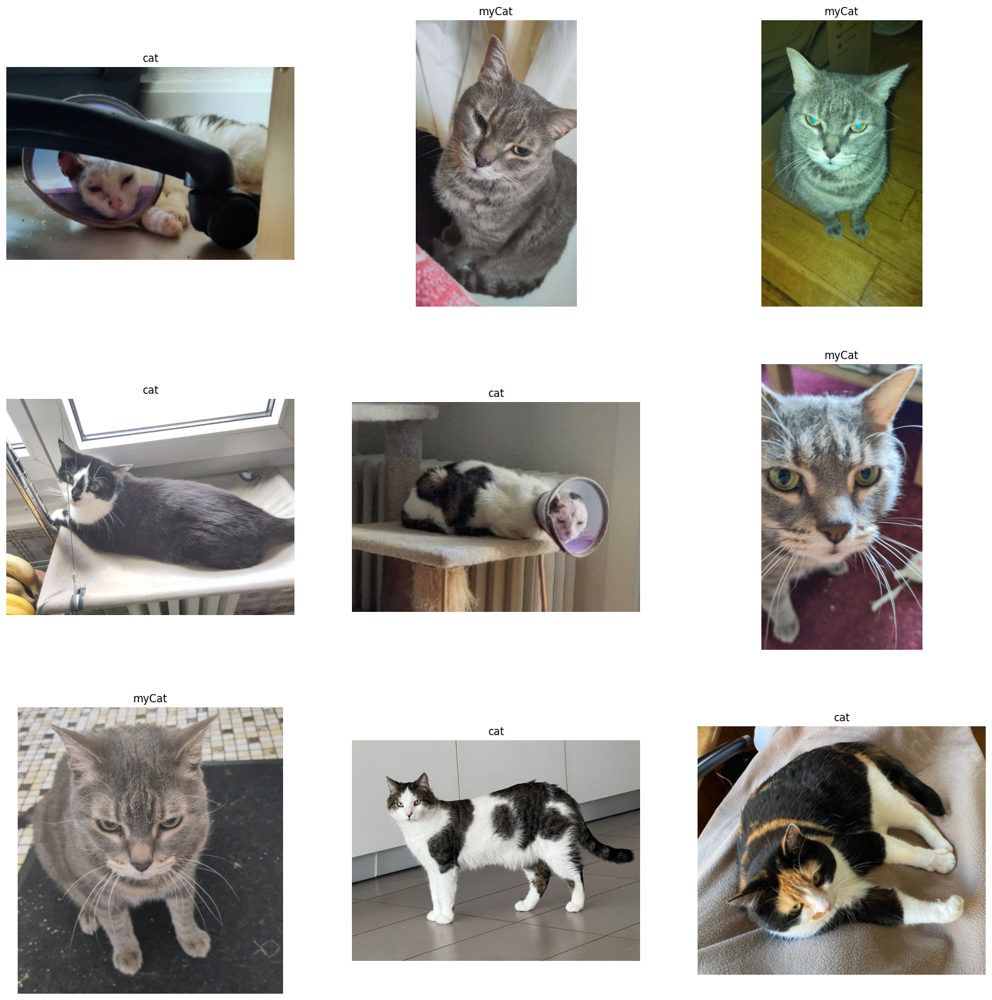

In [ ]:
plt.figure(figsize=(20, 20))

i = 0
for _, rowdata in train_df.sample(frac=1).head(9).iterrows():
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(PIL.Image.open(rowdata.path))
    plt.title(rowdata.label)
    plt.axis("off")
    i += 1

## Explore your dataset

Count the number of examples per classes and plot an histogram of it

In [ ]:
def create_histogram_counts(data, histogram_title):
  counts = data['label'].value_counts()
  print(counts)
  plt.figure(figsize=(10, 6))
  plt.bar(counts.index, counts.values)
  plt.xlabel('Class')
  plt.ylabel('Count')
  plt.title(histogram_title)
  plt.xticks(rotation=45)
  plt.show()
  print()

label
cat      26
myCat    19
Name: count, dtype: int64


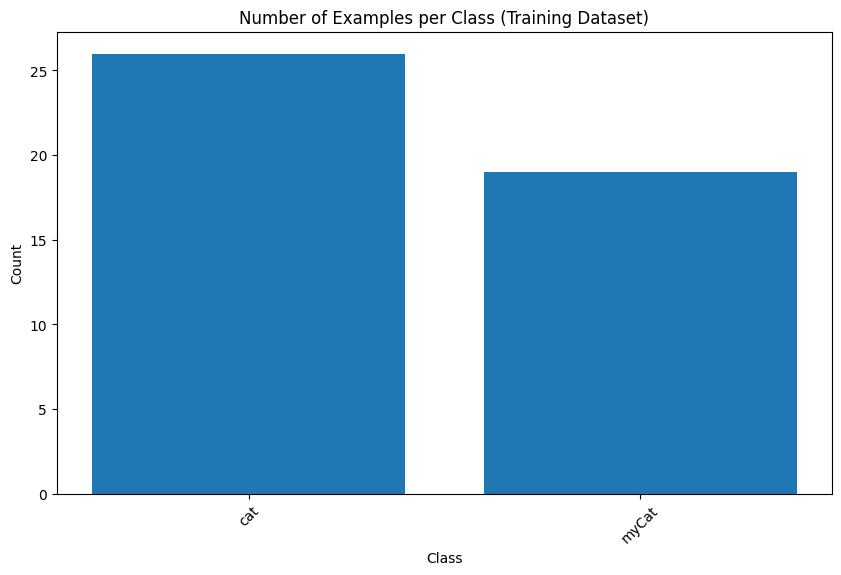


label
myCat    6
cat      6
Name: count, dtype: int64


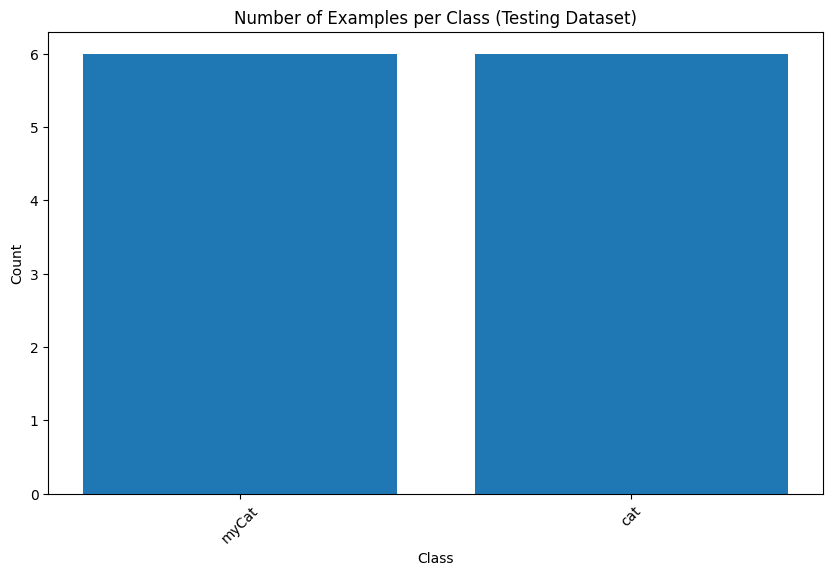

In [ ]:
create_histogram_counts(train_df, "Number of Examples per Class (Training Dataset)")
create_histogram_counts(test_df, "Number of Examples per Class (Testing Dataset)")

## Preprocessing steps

In [ ]:
IMG_HEIGHT = 224
IMG_WIDTH = 224

image_preprocesses = Sequential([
    Resizing(IMG_HEIGHT, IMG_WIDTH, crop_to_aspect_ratio=True),
    Rescaling(1. / 255)
])

image_augmentations = Sequential([
    RandomFlip(mode='horizontal'),  # Randomly flip images horizontally
    RandomRotation(factor=0.2),  # Randomly rotate images by a maximum of 20 degrees
    RandomZoom(height_factor=0.2, width_factor=0.2)  # Randomly zoom images by a maximum of 20% in height and width
])

def open_images(paths):
    return np.stack([
        open_image(path) for path in paths
    ])

def open_image(path):
    with PIL.Image.open(path) as image:
        opened_img = image_preprocesses(np.asarray(image))

    return opened_img

def augment_images(images):
    return np.stack([
        image_augmentations(img) for img in images
    ])

Plot examples of preprocessed and augmented images

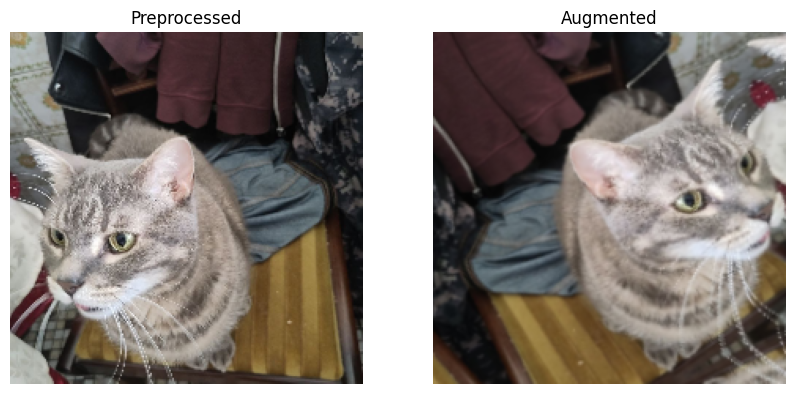

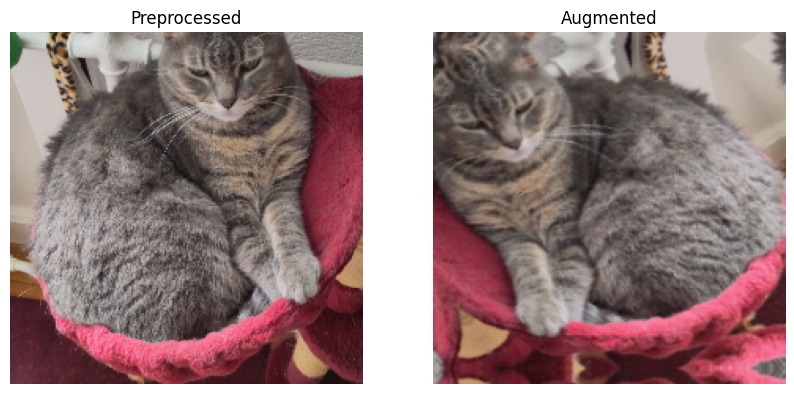

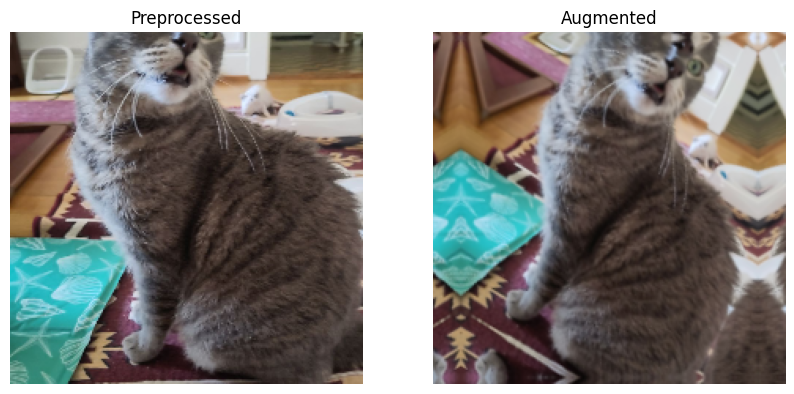

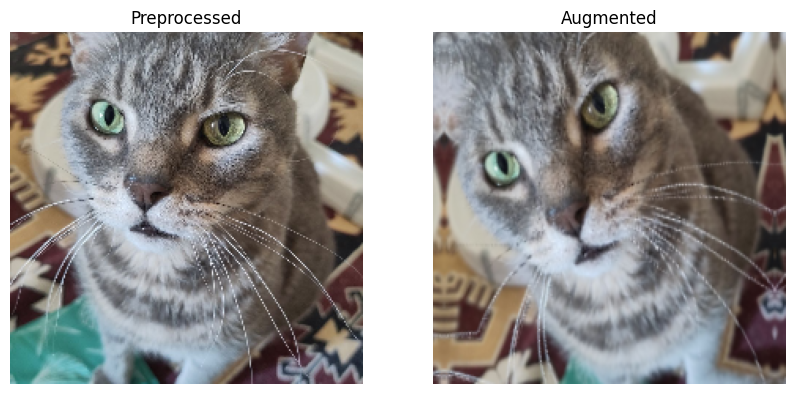

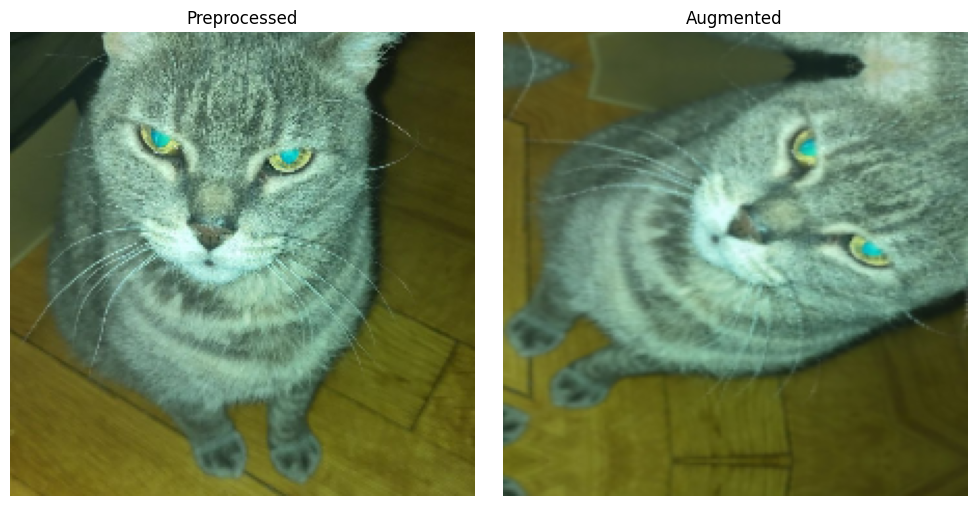

In [ ]:
for i in range(5):
  image_path = train_df['path'].iloc[i]
  image = open_image(image_path)
  augmented_image = augment_images([image])

  fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10, 5))
  axes[0].imshow(image)
  axes[0].set_title('Preprocessed')
  axes[0].axis('off')
  axes[1].imshow(augmented_image[0])
  axes[1].set_title('Augmented')
  axes[1].axis('off')

plt.tight_layout()
plt.show()

## Define model

In [ ]:
def get_model():
    base_model = MobileNetV2(
        input_shape=(224, 224, 3),
        weights='imagenet',
        include_top=False
    )

    layers = base_model.output

    added_layers = [
        # important, we need global average pooling instead of flatten for class activation map later on
        GlobalAveragePooling2D(),
        Dense(512, activation='relu'),
        Dropout(0.2),
        Dense(256, activation='relu'),
        Dense(len(LABEL_NAMES), activation='softmax')
    ]

    model = Model(inputs=base_model.input, outputs=Sequential(added_layers)(layers))

    for layer in base_model.layers:
        layer.trainable = False

    model.compile(
      optimizer = RMSprop(),
      loss = SparseCategoricalCrossentropy(),
      metrics = ['acc']
    )

    return model

In [ ]:
#get_model().summary()

## Model training

Cross-validation

**NOTE**: you shouldn't augment validations images. What we want to evaluate is the performances on "real" images, not on images that are augmented and change all the time

In [ ]:
# Hyper param:
rdm_state = 1234

NB_EPOCHS = 16
BATCH_SIZE = 14

In [ ]:
shuffled_dataset = train_df.sample(frac=1, random_state=rdm_state).reset_index(drop=True)

# Filter out rows where 'path' is a directory before splitting
filtered_shuffled_dataset = shuffled_dataset[shuffled_dataset['path'].apply(os.path.isfile)]

dataset_paths = filtered_shuffled_dataset['path'].to_numpy()
dataset_labels = filtered_shuffled_dataset['label'].to_numpy()

total_train_paths, test_paths, total_train_labels, test_labels = train_test_split(
    dataset_paths, dataset_labels, test_size=0.2, random_state=rdm_state
)

# We need to convert from string labels to integers
label_encoder = LabelEncoder()
# Fit on the unique labels from the filtered dataset to ensure all potential labels are covered.
label_encoder.fit(pd.unique(filtered_shuffled_dataset['label']))
total_train_labels = label_encoder.transform(total_train_labels)
test_labels = label_encoder.transform(test_labels)


train_losses = []
train_accuracies = []
val_losses = []
val_accuracies = []

# Augment images
total_images = open_images(total_train_paths)
total_images = np.concatenate((total_images,
                               augment_images(open_images(total_train_paths)),
                               augment_images(open_images(total_train_paths))),
                               axis=0)
total_labels_1 = total_train_labels
total_labels = np.append(total_labels_1, total_labels_1)
total_labels = np.append(total_labels, total_labels_1)


for train_index, val_index in KFold(n_splits=5).split(total_images, total_labels):

    # Corrected: val_images and val_labels should come from the KFold split of total_images/total_labels
    val_images = total_images[val_index]
    val_labels = total_labels[val_index]

    model = get_model() # We reinitialize the model

    history = model.fit(
        x=total_images[train_index],
        y=total_labels[train_index],
        batch_size=BATCH_SIZE,
        validation_data=[val_images, val_labels],
        epochs=NB_EPOCHS,
    )

    train_losses.append(history.history['loss'])
    val_losses.append(history.history['val_loss'])
    train_accuracies.append(history.history['acc'])
    val_accuracies.append(history.history['val_acc'])

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/16
7/7 ━━━━━━━━━━━━━━━━━━━━ 12s 910ms/step - acc: 0.5814 - loss: 3.1636 - val_acc: 0.7727 - val_loss: 0.4214
Epoch 2/16
7/7 ━━━━━━━━━━━━━━━━━━━━ 4s 614ms/step - acc: 0.8953 - loss: 0.1885 - val_acc: 1.0000 - val_loss: 0.0500
Epoch 3/16
7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 525ms/step - acc: 1.0000 - loss: 0.0192 - val_acc: 1.0000 - val_loss: 0.0275
Epoch 4/16
7/7 ━━━━━━━━━━━━━━━━━━━━ 6s 624ms/step - acc: 1.0000 - loss: 0.0067 - val_acc: 1.0000 - val_loss: 0.0162
Epoch 5/16
7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 823ms/step - acc: 1.0000 - loss: 0.0039 - val_acc: 1.0000 - val_loss: 0.0106
Epoch 6/16
7/7 ━━━━━━━━━━━━━━━━━━━━ 6s 988ms/step - acc: 1.0000 - loss: 0.0023 - val_acc: 1.0000 - val_loss: 0.0108
Epoch 7/16
7/7 ━━━━━━━━━━━━━━━━━━━━ 7s 522ms/step - acc: 1.0000 - loss: 8.2977e-04 - val_acc: 1.0000 - val_loss: 0.0060
Epoch 8/16
7/7 ━━━━━━━━━━━━━━━━━━━━ 4s 598ms/step - acc: 1.0000 - loss: 0.0012 - val_acc: 1.0000 - val_loss: 0.0087
Epoch 9/16
7/7 ━━━

## Results

Plot the results from your crossvalidation

In [ ]:
def plot_kfold_mean_performance(ax, train_performances, val_performances, measure_name):
    train_mean = np.mean(train_performances, axis=0)
    val_mean = np.mean(val_performances, axis=0)
    train_sd = np.std(train_performances, axis=0)
    val_sd = np.std(val_performances, axis=0)

    ax.fill_between(np.arange(1, NB_EPOCHS + 1), train_mean, train_mean+train_sd, facecolor='blue', alpha=0.5, label='Train')
    ax.fill_between(np.arange(1, NB_EPOCHS + 1), train_mean, train_mean-train_sd, facecolor='blue', alpha=0.5)

    ax.fill_between(np.arange(1, NB_EPOCHS + 1), val_mean, val_mean+val_sd, facecolor='orange', alpha=0.5, label='Val')
    ax.fill_between(np.arange(1, NB_EPOCHS + 1), val_mean, val_mean-val_sd, facecolor='orange', alpha=0.5)

    ax.set_xticks(np.arange(1, NB_EPOCHS + 1))

    ax.set_ylabel(measure_name)
    ax.set_xlabel('Number of epochs')
    #pl.title(str(K)+'-fold CV with '+str(n)+' hidden neurons')
    ax.legend()
    ax.grid()

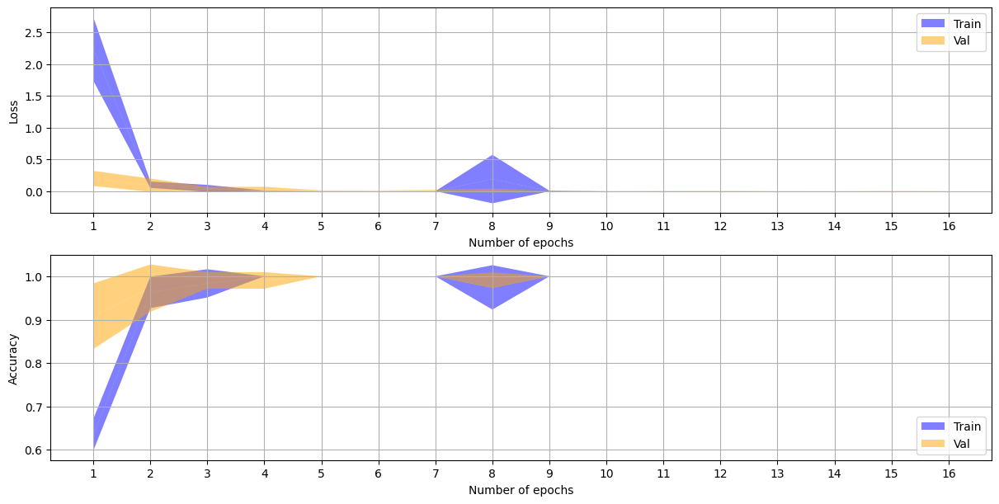

In [ ]:
fig, axs = plt.subplots(2, 1, constrained_layout=True, figsize=(12,6))

plot_kfold_mean_performance(axs[0], train_losses, val_losses, "Loss")
plot_kfold_mean_performance(axs[1], train_accuracies, val_accuracies, "Accuracy")

## Evaluate model on test set

In [ ]:
# First retrain model on all the training data
train_images = open_images(total_train_paths)
train_labels = total_train_labels

NB_EPOCHS = 14

model = get_model() # We reinitialize the model

history = model.fit(
    x=train_images,
    y=train_labels,
    batch_size=BATCH_SIZE,
    epochs=NB_EPOCHS,
)

Epoch 1/14
3/3 ━━━━━━━━━━━━━━━━━━━━ 7s 372ms/step - acc: 0.5833 - loss: 2.1482
Epoch 2/14
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 337ms/step - acc: 0.9444 - loss: 0.1698
Epoch 3/14
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 361ms/step - acc: 0.7222 - loss: 0.8005
Epoch 4/14
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 349ms/step - acc: 1.0000 - loss: 0.0258
Epoch 5/14
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 360ms/step - acc: 1.0000 - loss: 0.0144
Epoch 6/14
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 521ms/step - acc: 1.0000 - loss: 0.0093
Epoch 7/14
3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 377ms/step - acc: 1.0000 - loss: 0.0060
Epoch 8/14
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 367ms/step - acc: 1.0000 - loss: 0.0064
Epoch 9/14
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 355ms/step - acc: 1.0000 - loss: 0.0042
Epoch 10/14
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 357ms/step - acc: 1.0000 - loss: 0.0030
Epoch 11/14
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 344ms/step - acc: 1.0000 - loss: 0.0025
Epoch 12/14
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 375ms/step - acc: 1.0000 - loss: 0.0016
Epoch 13/14
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 358ms/ste

In [ ]:
# Empty a bit the memory
import gc

del train_images
del train_labels
gc.collect()

32312

In [ ]:
shuffled_dataset = test_df.sample(frac=1, random_state=1234).reset_index(drop=True) # random_state=6

# Filter out rows where 'path' is a directory before splitting
filtered_shuffled_dataset = shuffled_dataset[shuffled_dataset['path'].apply(os.path.isfile)]

#print(len(shuffled_dataset))

dataset_paths = filtered_shuffled_dataset['path'].to_numpy()
dataset_labels = filtered_shuffled_dataset['label'].to_numpy()


print(dataset_labels)
#LABEL_NAMES = pd.unique(dataset_labels)
print(LABEL_NAMES)

# We need to convert from string labels to integers
label_encoder = LabelEncoder()
label_encoder.fit(LABEL_NAMES) # Fit on the global LABEL_NAMES to ensure consistent mapping
test_labels = label_encoder.transform(dataset_labels)

test_images = open_images(dataset_paths)

pred = model.predict(test_images)
pred = np.argmax(pred, axis=-1)

test_confusion_matrix = me.confusion_matrix(test_labels, pred, labels=np.arange(len(LABEL_NAMES)))

['cat' 'cat' 'cat' 'myCat' 'cat' 'cat' 'myCat' 'myCat' 'myCat' 'myCat'
 'cat' 'myCat']
['cat' 'myCat']
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


In [ ]:
#F-score
dim = len(test_confusion_matrix)

for x in range(dim):
    col = 0
    lin = 0
    for y in range(dim) :
      if y != x :
        col += test_confusion_matrix[y][x]
        lin += test_confusion_matrix[x][y]

    TP = test_confusion_matrix[x][x]
    # Handle division by zero for precision and recall
    precision = TP / (TP + col) if (TP + col) != 0 else 0
    recall = TP / (TP + lin) if (TP + lin) != 0 else 0
    fScore = (2 * precision * recall) / (precision + recall) if (precision + recall) != 0 else 0
    print('F-Score', LABEL_NAMES[x].rjust(12), '(' + str(x) + ')', ':', fScore)

F-Score          cat (0) : 0.6666666666666667
F-Score        myCat (1) : 0.4444444444444444


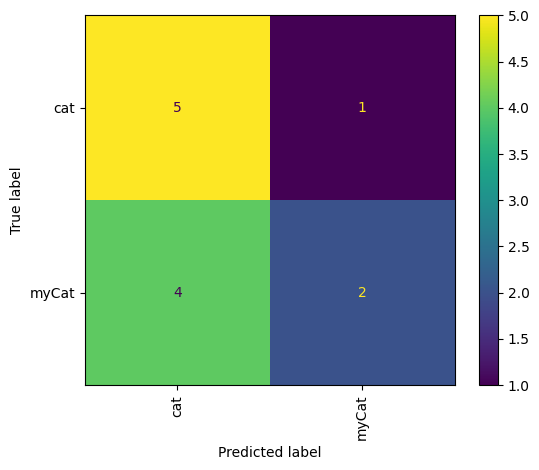

In [ ]:
confusion_matrix_display = me.ConfusionMatrixDisplay(
    confusion_matrix=test_confusion_matrix,
    display_labels=LABEL_NAMES,
)

confusion_matrix_display.plot(xticks_rotation='vertical')
plt.show()

## Display some misclassified images

Display some misclassified images to be able to see what images are difficult for the model

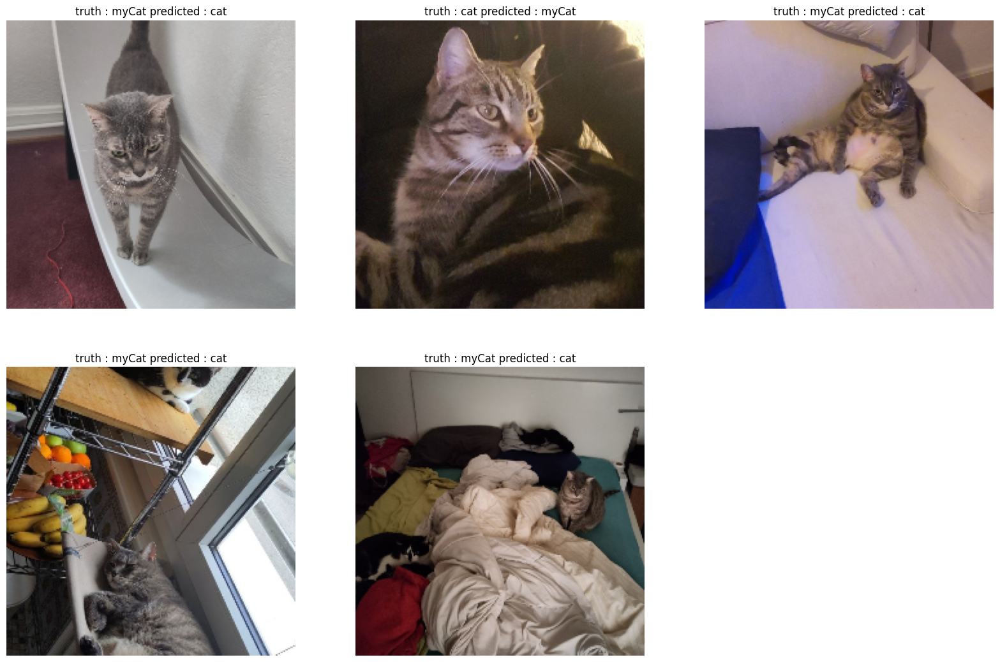

In [ ]:
mislabel_indices = np.where(test_labels != pred)[0] #!= for missclassified
plt.figure(figsize=(20, 20))

i = 0
rowOrCol = 3
#If we want to only have the nth first elements, use mislabel_indices[:n]
for index in mislabel_indices[:rowOrCol*rowOrCol]:
    ax = plt.subplot(rowOrCol, rowOrCol, i + 1)
    plt.imshow(test_images[index])
    plt.title("truth : " + LABEL_NAMES[test_labels[index]] + " predicted : " + LABEL_NAMES[pred[index]])
    plt.axis("off")
    i += 1

## Use grad-cam to inspect how the model classify


Here we can see an heatmap of the regions that activates the model the most.

### For more information:
- tf-keras-vis documentation: https://keisen.github.io/tf-keras-vis-docs/
- Grad-cam paper: https://arxiv.org/pdf/1610.02391.pdf
- Grad-cam++ paper: https://arxiv.org/pdf/1710.11063.pdf

Display heat map gradient:

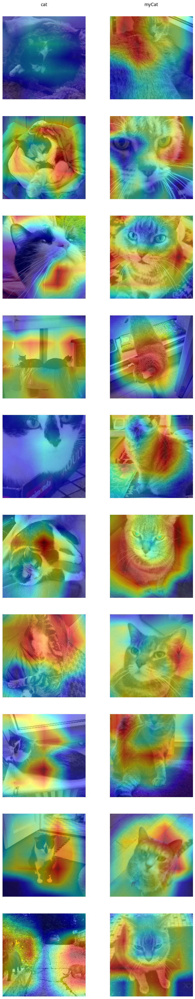

In [ ]:
# Create GradCAM++ object
gradcam = GradcamPlusPlus(
    model,
    model_modifier=ReplaceToLinear(),
    clone=True,
)

nb_images_per_class = 10

fig, axs = plt.subplots(nb_images_per_class, len(LABEL_NAMES), figsize=(len(LABEL_NAMES) * 5, nb_images_per_class * 5))

for label_idx, label_name in enumerate(LABEL_NAMES):
    axs[0,label_idx].set_title(label_name, loc='center', y=1.1)

    i = 0
    for _, rowdata in train_df[train_df['label'] == label_name].sample(frac=1).head(nb_images_per_class).iterrows():
        img = open_image(rowdata.path)
        predGradCam = model(np.expand_dims(img, axis=0))

        # Generate cam with GradCAM++
        score = CategoricalScore(np.argmax(predGradCam))
        cam = gradcam(score, img)
        heatmap = np.uint8(cm.jet(cam[0])[..., :3] * 255)

        axs[i,label_idx].imshow(img, vmin=0, vmax=1)
        axs[i,label_idx].imshow(heatmap, cmap='jet', alpha=0.5) # overlay
        axs[i,label_idx].axis("off")

        i += 1

## Grad-cam on misclassified images

Now do the same than above, but with the misclassified images. You shouldn't change anything pertaining to grad-cam besides on which image and prediction you do it

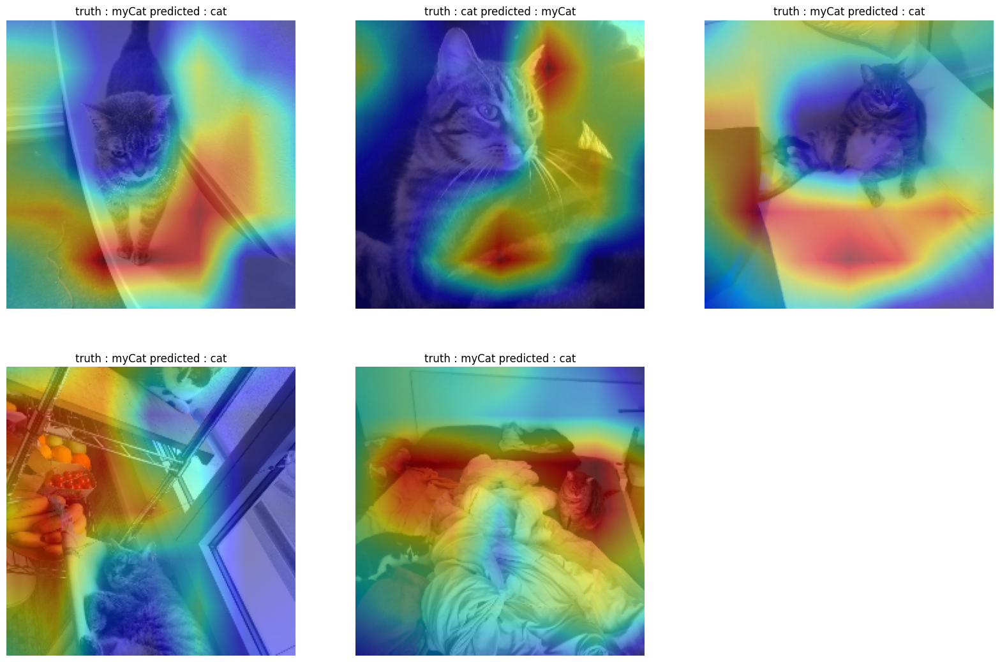

In [ ]:
# Create GradCAM++ object
gradcam = GradcamPlusPlus(
    model,
    model_modifier=ReplaceToLinear(),
    clone=True,
)

nb_images_per_class = 10


plt.figure(figsize=(20, 20))

i = 0
#If we want to only have the nth first elements, use mislabel_indices[:n]
for index in mislabel_indices[:rowOrCol*rowOrCol]:
    ax = plt.subplot(rowOrCol, rowOrCol, i + 1)

    # Generate cam with GradCAM++
    score = CategoricalScore(np.argmax(pred[index]))
    cam = gradcam(score, test_images[index])
    heatmap = np.uint8(cm.jet(cam[0])[..., :3] * 255)

    plt.imshow(test_images[index])
    plt.imshow(heatmap, cmap='jet', alpha=0.5) # overlay
    plt.title("truth : " + LABEL_NAMES[test_labels[index]] + " predicted : " + LABEL_NAMES[pred[index]])
    plt.axis("off")
    i += 1

Try to determine what caused the misclassifcations and what you can do about it

`update here to keep trace of your modifications:` (double-clic)

## Final part

Now we can use the model with custom pictures and test how it works or not.

In [ ]:
usage_folder_path = "dataset_end" # update to fit images folder name

To add pictures from internet uncomment following cell

In [ ]:
# QUERIES = ["cat"]
# nbr = 25
# download_queries(QUERIES, usage_folder_path, nbr)

To add pictures from local uncomment following cell

In [ ]:
# for train_class in classes:
#   print("for", train_class, "import end test pictures:")
#   upload_pictures(usage_folder_path + '/' + train_class)

Convert png to jpg & create dataframe:

In [ ]:
png_to_jpg(usage_folder_path)

end_df = create_dataframe_from_directories(usage_folder_path)

number of png found and resized in jpg : 0


Compute F-score and confusion matrix with the new folder:

['myCat' 'myCat' 'myCat' 'myCat' 'cat' 'myCat' 'myCat' 'myCat' 'myCat'
 'myCat' 'myCat' 'cat' 'myCat' 'myCat' 'cat' 'myCat' 'myCat' 'cat' 'myCat'
 'myCat' 'cat' 'myCat' 'myCat' 'myCat' 'cat' 'myCat' 'myCat' 'myCat'
 'myCat' 'myCat' 'myCat' 'myCat']
['cat' 'myCat']
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
F-Score          cat (0) : 0.7142857142857143
F-Score        myCat (1) : 0.9199999999999999


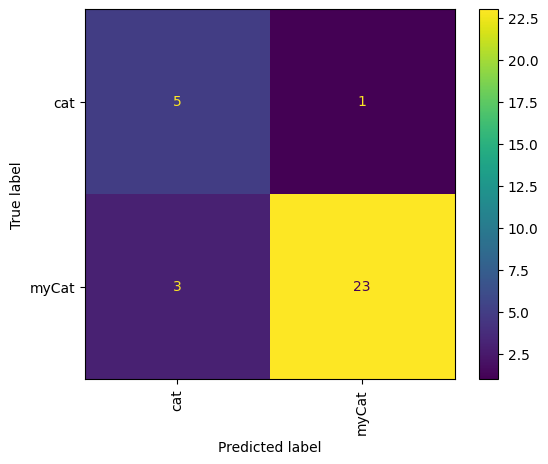

In [ ]:
#print(len(end_df))

shuffled_dataset = end_df.sample(frac=1, random_state=1234).reset_index(drop=True)

# Filter out rows where 'path' is a directory before splitting
filtered_shuffled_dataset = shuffled_dataset[shuffled_dataset['path'].apply(os.path.isfile)]

#print(len(shuffled_dataset))

dataset_paths = filtered_shuffled_dataset['path'].to_numpy()
dataset_labels = filtered_shuffled_dataset['label'].to_numpy()


print(dataset_labels)
#LABEL_NAMES = pd.unique(dataset_labels)
print(LABEL_NAMES)

# We need to convert from string labels to integers
label_encoder = LabelEncoder()
label_encoder.fit(dataset_labels)
end_labels = label_encoder.transform(dataset_labels)

end_images = open_images(dataset_paths)

pred = model.predict(end_images)
pred = np.argmax(pred, axis=-1)

end_confusion_matrix = me.confusion_matrix(end_labels, pred, labels=np.arange(len(LABEL_NAMES)))


dim = len(end_confusion_matrix)

for x in range(dim):
    col = 0
    lin = 0
    for y in range(dim) :
      if y != x :
        col += end_confusion_matrix[y][x]
        lin += end_confusion_matrix[x][y]

    TP = end_confusion_matrix[x][x]
    # Handle division by zero for precision and recall
    precision = TP / (TP + col) if (TP + col) != 0 else 0
    recall = TP / (TP + lin) if (TP + lin) != 0 else 0
    fScore = (2 * precision * recall) / (precision + recall) if (precision + recall) != 0 else 0
    print('F-Score', LABEL_NAMES[x].rjust(12), '(' + str(x) + ')', ':', fScore)


confusion_matrix_display = me.ConfusionMatrixDisplay(
    confusion_matrix=end_confusion_matrix,
    display_labels=LABEL_NAMES,
)

confusion_matrix_display.plot(xticks_rotation='vertical')
plt.show()

Display whole images given with prediction and truth:

Summary of Custom Image Classification:
Total Images: 32
Correctly Classified Images: 28
Accuracy: 87.50%



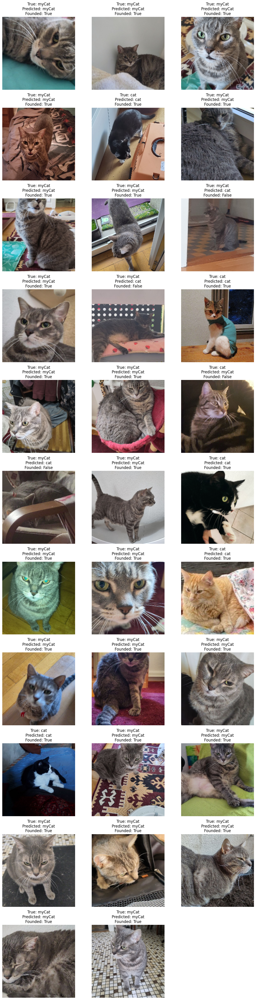

In [ ]:
correct_predictions = np.sum(end_labels == pred)
total_images = len(end_labels)

print(f"Summary of Custom Image Classification:")
print(f"Total Images: {total_images}")
print(f"Correctly Classified Images: {correct_predictions}")
print(f"Accuracy: {correct_predictions / total_images:.2%}\n")

# Calculate dynamic grid size
n_cols = 3  # You can adjust the number of columns
n_rows = (total_images + n_cols - 1) // n_cols # Calculate rows needed

plt.figure(figsize=(n_cols * 4, n_rows * 4)) # Adjust figure size dynamically

for i in range(total_images):
    ax = plt.subplot(n_rows, n_cols, i + 1)
    plt.imshow(end_images[i])
    is_same = end_labels[i] == pred[i]
    plt.title(f"True: {LABEL_NAMES[end_labels[i]]}\nPredicted: {LABEL_NAMES[pred[i]]}\nFounded: {is_same}")
    plt.axis("off")

plt.tight_layout()
plt.show()

## Mobile

Adapt for Mobile - https://github.com/SimWalther/TFLClassify

In [ ]:
# Commented out IPython magic to ensure Python compatibility.
%pip install tflite-support
%pip install tflite_support_nightly

In [ ]:

# Commented out IPython magic to ensure Python compatibility.
#%pip install tflite-support
#%pip install tflite_support_nightly
import tensorflow as tf

from tflite_support.metadata_writers import image_classifier
from tflite_support.metadata_writers import writer_utils


# Task Library expects label files that are in the same format as the one below.
LABEL_FILE = "labels.txt"
SAVE_TO_PATH = "MyModel.tflite"

# Create the labels file
with open(LABEL_FILE, 'w') as label_file:
    for label in LABEL_NAMES: # /!\ class_names variable must contains the names of the labels you have.
        label_file.write("{}\n".format(label))

tflite_model = tf.lite.TFLiteConverter.from_keras_model(model).convert()

# Save the model.
with open(SAVE_TO_PATH, 'wb') as f:
    f.write(tflite_model)

ImageClassifierWriter = image_classifier.MetadataWriter

# Normalization parameters is required when reprocessing the image. It is
# optional if the image pixel values are in range of [0, 255] and the input
# tensor is quantized to uint8. See the introduction for normalization and
# quantization parameters below for more details.
# https://www.tensorflow.org/lite/convert/metadata#normalization_and_quantization_parameters)
INPUT_NORM_MEAN = 127.5
INPUT_NORM_STD = 127.5

# Create the metadata writer.
writer = ImageClassifierWriter.create_for_inference(
    writer_utils.load_file(SAVE_TO_PATH),
    [INPUT_NORM_MEAN],
    [INPUT_NORM_STD],
    [LABEL_FILE]
)

# Verify the metadata generated by metadata writer.
print(writer.get_metadata_json())

# Populate the metadata into the model.
writer_utils.save_file(writer.populate(), SAVE_TO_PATH)
